# The University of Azad Jammu and Kashmir
**Department of Software Engineering — Digital Image Processing Lab**
Lab Instructor: Engr. Fahad Nisar | Semester: Fifth | Session: 2024-28 (SE)

---
**Name:** `<Muneeba Arshad>`  
**Roll No:** `2024-SE-06>` 

---
# Lab Task # 04 — Geometric Transformations with Custom Inputs
Assigned: November 05, 2026 | Due: November 12, 2026, 11:59 PM

**Objective:** build one reusable `transform(image, operation, **params)` function that accepts custom values, validates every input, and produces correct geometric transformations (scaling, cropping, flipping, translation, rotation).

**Contents**
1. Setup and declared limits
2. Error type and validation helpers
3. Load and validate the image
4. The reusable `transform` function
5. Display / save helpers
6. Interactive input (user chooses operation and parameters)
7. Demonstration of every operation (custom values)
8. Interpolation comparison
9. Rejected (invalid) inputs and accepted boundary inputs
10. Identity and correctness checks
11. Explanations: coordinates vs indexing, aspect ratio, canvas expansion, translation clipping
12. Saved files and conclusion

## 1. Setup and declared limits

In [1]:
import os, math, hashlib, textwrap, itertools
import numpy as np
import cv2
import matplotlib.pyplot as plt

INPUT_PATH = "input_image.png"     # change this path to use another image
SAVE_DIR   = "saved_results"       # every transformed result is saved here
os.makedirs(SAVE_DIR, exist_ok=True)

# ---- Declared and enforced maximum output size (checked inside transform) ----
MAX_SIDE   = 8000                  # maximum width OR height of any output, in pixels
MAX_PIXELS = 25_000_000            # maximum total pixels (width x height) of any output

# ---- Colour handling: every array in this notebook is RGB, uint8, shape (H, W, 3) ----
BACKGROUND_COLOR = (0, 0, 0)       # RGB fill for areas exposed by translation / rotation

print("NumPy", np.__version__, "| OpenCV", cv2.__version__)
print(f"Declared output limits: each side <= {MAX_SIDE} px, total <= {MAX_PIXELS:,} px")
print("Colour convention: RGB, uint8, array shape (height, width, 3)")

NumPy 2.4.6 | OpenCV 5.0.0
Declared output limits: each side <= 8000 px, total <= 25,000,000 px
Colour convention: RGB, uint8, array shape (height, width, 3)


## 2. Error type and validation helpers
All problems raise one exception type, `TransformError`, with a clear message. Nothing is silently replaced by a default value.

* `check_number` — real finite number (rejects text, `None`, booleans, NaN, ±infinity; **zero and negative values are allowed**).
* `check_integer` — whole number (used for crop coordinates).
* `check_choice` / `check_bool` — restricted choices.
* `parse_*` — convert **typed text** (from prompts) into values, with the same strictness.

In [2]:
class TransformError(ValueError):
    """Raised for an invalid image, operation name or parameter."""

OPERATIONS     = ("scale", "crop", "flip", "translate", "rotate")
INTERPOLATIONS = {"nearest":  cv2.INTER_NEAREST,
                  "bilinear": cv2.INTER_LINEAR,
                  "bicubic":  cv2.INTER_CUBIC,
                  "lanczos":  cv2.INTER_LANCZOS4}
FLIP_DIRECTIONS = ("horizontal", "vertical", "both")

# Required parameters of each operation: (name, prompt text, kind)
OPERATION_SPECS = {
    "scale":     [("fx", "Horizontal scale factor fx (number > 0, e.g. 1.5)", "float"),
                  ("fy", "Vertical scale factor fy (number > 0, e.g. 0.5)", "float"),
                  ("interpolation", "Interpolation (nearest / bilinear / bicubic / lanczos)", ("choice", tuple(INTERPOLATIONS)))],
    "crop":      [("left",   "Left   x coordinate (integer)", "int"),
                  ("top",    "Top    y coordinate (integer)", "int"),
                  ("right",  "Right  x coordinate (integer, exclusive)", "int"),
                  ("bottom", "Bottom y coordinate (integer, exclusive)", "int")],
    "flip":      [("direction", "Direction (horizontal / vertical / both)", ("choice", FLIP_DIRECTIONS))],
    "translate": [("tx", "Horizontal offset tx in pixels (+ right, - left)", "float"),
                  ("ty", "Vertical offset ty in pixels (+ down, - up)", "float")],
    "rotate":    [("angle",  "Angle in degrees (+ = counter-clockwise, - = clockwise)", "float"),
                  ("expand", "Expand canvas to fit the whole rotated image? (yes / no)", "bool")],
}

# ------------------------- checks used INSIDE transform -------------------------
def validate_image(image):
    """Image must be a non-empty RGB uint8 array (H, W, 3). Returns (width, height)."""
    if not isinstance(image, np.ndarray):
        raise TransformError(f"image must be a NumPy array, got {type(image).__name__}")
    if image.dtype != np.uint8 or image.ndim != 3 or image.shape[2] != 3:
        raise TransformError("image must be an RGB uint8 array of shape (height, width, 3); "
                             f"got dtype={image.dtype}, shape={image.shape}")
    if image.shape[0] == 0 or image.shape[1] == 0:
        raise TransformError(f"image has zero width or height (shape={image.shape})")
    return image.shape[1], image.shape[0]

def check_number(name, value):
    """Finite real number (int/float). Zero and negative values are valid."""
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, float, np.integer, np.floating)):
        raise TransformError(f"'{name}' must be a number, got {type(value).__name__} ({value!r})")
    try:
        value = float(value)
    except OverflowError:
        raise TransformError(f"'{name}' is too large to be a valid number")
    if not math.isfinite(value):
        raise TransformError(f"'{name}' must be finite (NaN and infinity are not allowed), got {value}")
    return value

def check_integer(name, value):
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)):
        raise TransformError(f"'{name}' must be an integer, got {type(value).__name__} ({value!r})")
    return int(value)

def check_choice(name, value, allowed):
    if not isinstance(value, str):
        raise TransformError(f"'{name}' must be text, one of {list(allowed)}; got {type(value).__name__} ({value!r})")
    cleaned = value.strip().lower()
    if cleaned not in allowed:
        raise TransformError(f"unsupported {name} {value!r}; choose one of {list(allowed)}")
    return cleaned

def check_bool(name, value):
    if not isinstance(value, (bool, np.bool_)):
        raise TransformError(f"'{name}' must be True or False, got {value!r}")
    return bool(value)

def check_output_size(new_w, new_h, what):
    """Reject empty outputs and enforce the declared maximum output size."""
    if new_w < 1 or new_h < 1:
        raise TransformError(f"{what} would give an empty image ({new_w}x{new_h}); both sides must be >= 1 pixel")
    if new_w > MAX_SIDE or new_h > MAX_SIDE:
        raise TransformError(f"{what} would give {new_w}x{new_h}, above the maximum side of {MAX_SIDE} px")
    if new_w * new_h > MAX_PIXELS:
        raise TransformError(f"{what} would give {new_w*new_h:,} pixels, above the maximum of {MAX_PIXELS:,}")

def normalise_operation(operation):
    if not isinstance(operation, str):
        raise TransformError(f"operation must be text, one of {list(OPERATIONS)}; got {operation!r}")
    name = operation.strip().lower()
    if name not in OPERATIONS:
        raise TransformError(f"unknown operation {operation!r}; supported operations: {list(OPERATIONS)}")
    return name

# ------------------------- parsing of TYPED text (prompts) -------------------------
def parse_float(text, name):
    s = str(text).strip()
    if s == "":
        raise TransformError(f"'{name}' is missing (empty input)")
    try:
        value = float(s)
    except ValueError:
        raise TransformError(f"'{name}': {s!r} is not a number")
    if not math.isfinite(value):
        raise TransformError(f"'{name}': NaN and infinity are not allowed (got {s!r})")
    return value

def parse_int(text, name):
    s = str(text).strip()
    if s == "":
        raise TransformError(f"'{name}' is missing (empty input)")
    try:
        return int(s)
    except ValueError:
        raise TransformError(f"'{name}': {s!r} is not a whole number (an integer such as 120 is required)")

def parse_bool(text, name):
    s = str(text).strip().lower()
    if s in ("yes", "y", "true", "t", "1"):
        return True
    if s in ("no", "n", "false", "f", "0"):
        return False
    raise TransformError(f"'{name}': {str(text).strip()!r} is not a valid yes/no choice")

def parse_param(name, kind, text):
    if isinstance(kind, tuple):                       # ("choice", allowed_values)
        return check_choice(name, str(text), kind[1])
    return {"float": parse_float, "int": parse_int, "bool": parse_bool}[kind](text, name)

def parse_text_params(operation, raw):
    """Turn a dict of typed strings into validated Python values for the operation."""
    op = normalise_operation(operation)
    specs = OPERATION_SPECS[op]
    names = [s[0] for s in specs]
    missing = [n for n in names if n not in raw]
    if missing:
        raise TransformError(f"missing required parameter(s) for '{op}': {missing}")
    extra = [k for k in raw if k not in names]
    if extra:
        raise TransformError(f"unexpected parameter(s) for '{op}': {extra}; expected {names}")
    return op, {name: parse_param(name, kind, raw[name]) for name, _, kind in specs}

## 3. Load and validate the image
`load_image` checks that the file **exists**, **decodes successfully**, and has **non-zero dimensions**. The image is converted from OpenCV's BGR to **RGB once**, so Matplotlib and every operation use the same colour order. The original array is made read-only and a SHA-256 fingerprint is stored, so we can prove later that it was never modified.

The input image is a sunset over a mountain lake (generated by `generate_input_image.py`, included in the repository).

In [3]:
def load_image(path):
    """Load an image file as an RGB uint8 array after validating it."""
    if not isinstance(path, (str, os.PathLike)):
        raise ValueError(f"path must be text, got {type(path).__name__}")
    if not os.path.isfile(path):
        raise FileNotFoundError(f"image file not found: '{path}'")
    data = np.fromfile(path, dtype=np.uint8)
    if data.size == 0:
        raise ValueError(f"image file is empty: '{path}'")
    bgr = cv2.imdecode(data, cv2.IMREAD_COLOR)        # always 3 channels (BGR order)
    if bgr is None:
        raise ValueError(f"file could not be decoded as an image: '{path}'")
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)         # one consistent colour order: RGB
    validate_image(rgb)                                # non-zero width and height
    return rgb

# --- demonstrate the three load checks (each must be rejected) ---
with open("fake_not_an_image.png", "wb") as f:
    f.write(b"this is plain text, not image data")
try:
    for label, path in [("missing file", "no_such_image.png"), ("undecodable file", "fake_not_an_image.png")]:
        try:
            load_image(path)
        except (FileNotFoundError, ValueError) as err:
            print(f"{label:17s} -> rejected: {err}")
finally:
    os.remove("fake_not_an_image.png")
try:
    validate_image(np.zeros((0, 50, 3), np.uint8))
except TransformError as err:
    print(f"{'zero-size array':17s} -> rejected: {err}")

missing file      -> rejected: image file not found: 'no_such_image.png'
undecodable file  -> rejected: file could not be decoded as an image: 'fake_not_an_image.png'
zero-size array   -> rejected: image has zero width or height (shape=(0, 50, 3))


Loaded 'input_image.png'
Width       : 960 px
Height      : 640 px
Array shape : (640, 960, 3)   -> (rows = height, columns = width, channels)
dtype       : uint8, colour order: RGB, aspect ratio (w/h) = 1.500


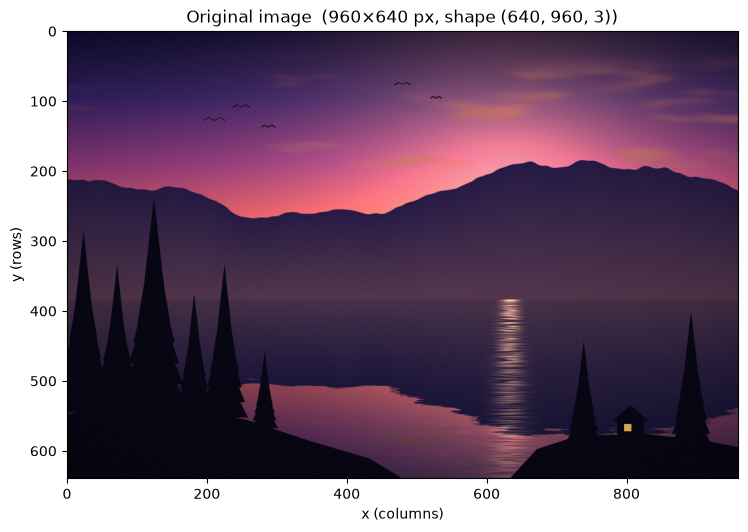

In [4]:
original = load_image(INPUT_PATH)
original.flags.writeable = False                       # the original can never be modified in place
original_digest = hashlib.sha256(original.tobytes()).hexdigest()
H, W = original.shape[:2]

print(f"Loaded '{INPUT_PATH}'")
print(f"Width       : {W} px")
print(f"Height      : {H} px")
print(f"Array shape : {original.shape}   -> (rows = height, columns = width, channels)")
print(f"dtype       : {original.dtype}, colour order: RGB, aspect ratio (w/h) = {W/H:.3f}")

plt.figure(figsize=(8, 5.4))
plt.imshow(original)
plt.title(f"Original image  ({W}×{H} px, shape {original.shape})")
plt.xlabel("x (columns)"); plt.ylabel("y (rows)")
plt.tight_layout(); plt.show()

## 4. The reusable `transform` function
`transform(image, operation, **params)` is the **single entry point**. It validates the image, the operation name and *all* parameters itself (so it is safe even when called directly, without the prompts), never changes its input, and always returns a **new** array.

| Operation | Parameters (all required) | Rule summary |
|---|---|---|
| `scale` | `fx`, `fy`, `interpolation` | finite factors > 0; output size = round(W·fx) × round(H·fy), each ≥ 1 px and within the declared maximum |
| `crop` | `left`, `top`, `right`, `bottom` | integers, 0 ≤ left < right ≤ W and 0 ≤ top < bottom ≤ H (right/bottom exclusive) |
| `flip` | `direction` | `horizontal`, `vertical` or `both` |
| `translate` | `tx`, `ty` | finite numbers (positive, negative or zero); canvas size unchanged |
| `rotate` | `angle`, `expand` | any finite angle (degrees); `expand` must be True/False; about the image centre; **positive = counter-clockwise** |

Translation and rotation use 2×3 **affine matrices** (`translation_matrix`, `rotation_matrix`) applied with `cv2.warpAffine`.

In [5]:
def translation_matrix(tx, ty):
    """2x3 affine matrix for a shift of (tx, ty) pixels (x to the right, y downward)."""
    return np.array([[1.0, 0.0, tx],
                     [0.0, 1.0, ty]], dtype=np.float64)

def rotation_matrix(width, height, angle, expand):
    """2x3 affine matrix rotating about the image centre ((w-1)/2, (h-1)/2).
    Positive angle = counter-clockwise on screen. Returns (M, out_width, out_height)."""
    cx, cy = (width - 1) / 2.0, (height - 1) / 2.0
    M = cv2.getRotationMatrix2D((cx, cy), angle, 1.0)
    out_w, out_h = width, height
    if expand:                                          # canvas that holds the whole rotated image
        c, s = abs(math.cos(math.radians(angle))), abs(math.sin(math.radians(angle)))
        out_w = math.ceil(round(width * c + height * s, 6))    # round(...,6) avoids 1e-16 noise at 90 deg
        out_h = math.ceil(round(width * s + height * c, 6))
        M[0, 2] += (out_w - width) / 2.0                # keep the rotated image centred on the new canvas
        M[1, 2] += (out_h - height) / 2.0
    return M, out_w, out_h

def _scale(image, width, height, fx, fy, interpolation):
    fx, fy = check_number("fx", fx), check_number("fy", fy)
    if fx <= 0 or fy <= 0:
        raise TransformError(f"scale factors must be greater than zero (got fx={fx:g}, fy={fy:g})")
    method = check_choice("interpolation", interpolation, INTERPOLATIONS)
    raw_w, raw_h = width * fx, height * fy
    if not (math.isfinite(raw_w) and math.isfinite(raw_h)):
        raise TransformError("scale factors are too large: the output size overflows")
    new_w, new_h = int(math.floor(raw_w + 0.5)), int(math.floor(raw_h + 0.5))    # round half up
    check_output_size(new_w, new_h, f"scaling by fx={fx:g}, fy={fy:g}")
    return cv2.resize(image, (new_w, new_h), interpolation=INTERPOLATIONS[method])

def _crop(image, width, height, left, top, right, bottom):
    left, top = check_integer("left", left), check_integer("top", top)
    right, bottom = check_integer("right", right), check_integer("bottom", bottom)
    if not (0 <= left < right <= width):
        raise TransformError(f"invalid crop columns: need 0 <= left < right <= width ({width}); got left={left}, right={right}")
    if not (0 <= top < bottom <= height):
        raise TransformError(f"invalid crop rows: need 0 <= top < bottom <= height ({height}); got top={top}, bottom={bottom}")
    return image[top:bottom, left:right].copy()          # array order is [rows, columns] = [y, x]

def _flip(image, width, height, direction):
    direction = check_choice("direction", direction, FLIP_DIRECTIONS)
    if direction == "horizontal":                        # mirror left <-> right
        return image[:, ::-1].copy()
    if direction == "vertical":                          # mirror top <-> bottom
        return image[::-1, :].copy()
    return image[::-1, ::-1].copy()                      # both

def _translate(image, width, height, tx, ty):
    tx, ty = check_number("tx", tx), check_number("ty", ty)
    if abs(tx) >= width or abs(ty) >= height:            # the whole image leaves the canvas
        return np.full_like(image, BACKGROUND_COLOR)
    return cv2.warpAffine(image, translation_matrix(tx, ty), (width, height), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=BACKGROUND_COLOR)

def _rotate(image, width, height, angle, expand):
    angle, expand = check_number("angle", angle), check_bool("expand", expand)
    M, out_w, out_h = rotation_matrix(width, height, angle % 360.0, expand)
    check_output_size(out_w, out_h, "rotation")
    return cv2.warpAffine(image, M, (out_w, out_h), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=BACKGROUND_COLOR)

_HANDLERS = {"scale": _scale, "crop": _crop, "flip": _flip, "translate": _translate, "rotate": _rotate}

def transform(image, operation, **params):
    """Apply one geometric operation and return the NEW transformed image.

    transform(img, "scale",     fx=1.5, fy=1.5, interpolation="bicubic")
    transform(img, "crop",      left=10, top=20, right=300, bottom=200)
    transform(img, "flip",      direction="horizontal")      # horizontal | vertical | both
    transform(img, "translate", tx=40, ty=-25)
    transform(img, "rotate",    angle=30, expand=True)       # + = counter-clockwise
    """
    width, height = validate_image(image)
    op = normalise_operation(operation)
    required = [spec[0] for spec in OPERATION_SPECS[op]]
    missing = [n for n in required if n not in params]
    if missing:
        raise TransformError(f"missing required parameter(s) for '{op}': {missing}")
    unexpected = [k for k in params if k not in required]
    if unexpected:
        raise TransformError(f"unexpected parameter(s) for '{op}': {unexpected}; expected {required}")
    return _HANDLERS[op](image, width, height, **params)

def transform_from_text(image, operation, **typed):
    """Parse typed text (as entered at a prompt), then call transform."""
    op, params = parse_text_params(operation, typed)
    return transform(image, op, **params)

print("Supported operations:", ", ".join(OPERATIONS))
print("Interpolations      :", ", ".join(INTERPOLATIONS))
print("Flip directions     :", ", ".join(FLIP_DIRECTIONS))

Supported operations: scale, crop, flip, translate, rotate
Interpolations      : nearest, bilinear, bicubic, lanczos
Flip directions     : horizontal, vertical, both


## 5. Display and save helpers
`show_comparison` draws the original next to the result with labels for the **operation, parameters and output dimensions**. `save_result` writes each result to `saved_results/`.

In [6]:
def format_params(params):
    return ", ".join(f"{k}={v:g}" if isinstance(v, float) else f"{k}={v}" for k, v in params.items())

def save_result(img, filename):
    path = os.path.join(SAVE_DIR, filename)
    if not cv2.imwrite(path, cv2.cvtColor(img, cv2.COLOR_RGB2BGR)):      # back to BGR only for writing
        raise IOError(f"could not write '{path}'")
    print(f"Saved -> {path}   ({img.shape[1]}x{img.shape[0]} px)")
    return path

def show_comparison(orig, result, operation, params, box=None):
    """Original vs transformed image with labels (operation, parameters, output size)."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
    axes[0].imshow(orig)
    axes[0].set_title(f"ORIGINAL\n{orig.shape[1]}×{orig.shape[0]} px", fontsize=10)
    if box is not None:                                                  # mark the crop window on the original
        l, t, r, b = box
        axes[0].add_patch(plt.Rectangle((l - 0.5, t - 0.5), r - l, b - t, fill=False, edgecolor="yellow", linewidth=2))
    axes[1].imshow(result)
    axes[1].set_title(f"{operation.upper()}  ({format_params(params)})\nOUTPUT {result.shape[1]}×{result.shape[0]} px", fontsize=10)
    for ax in axes:
        ax.set_xlabel("x (columns)"); ax.set_ylabel("y (rows)")
    plt.tight_layout(); plt.show()

def run_demo(operation, filename, box=None, **params):
    """transform -> labelled comparison -> save. Returns the result."""
    result = transform(original, operation, **params)
    show_comparison(original, result, operation, params, box)
    save_result(result, filename)
    return result

def print_table(headers, rows, widths):
    """Plain-text table with wrapped columns (renders the same everywhere)."""
    def fmt(cells):
        wrapped = [textwrap.wrap(str(c), w) or [""] for c, w in zip(cells, widths)]
        return "\n".join(" | ".join((col[i] if i < len(col) else "").ljust(w) for col, w in zip(wrapped, widths))
                         for i in range(max(len(col) for col in wrapped)))
    line = "-+-".join("-" * w for w in widths)
    print(fmt(headers)); print(line)
    for r in rows:
        print(fmt(r)); print(line)

## 6. Interactive input (operation and parameters typed by the user)
The user picks an operation and types its parameters at prompts. The typed text is **parsed and validated first** (`parse_param`), then the values are passed to `transform`, which validates them again. A wrong entry prints a clear message and the question is **asked again** — nothing crashes and nothing is replaced by a hidden default. Type `cancel` to abandon an operation and `quit` to leave.

The output below is a sample session (it deliberately includes wrong entries that get corrected). **Run the cell again to enter your own values.**

In [7]:
try:
    from IPython.core.error import StdinNotImplementedError
    INPUT_UNAVAILABLE = (EOFError, StdinNotImplementedError)
except ImportError:
    INPUT_UNAVAILABLE = (EOFError,)

class InputCancelled(Exception):
    pass

_session_counter = itertools.count(1)

def ask(prompt, name, kind):
    """Keep asking until the typed text is valid for this parameter."""
    while True:
        raw = input(f"{prompt}: ")
        if raw.strip().lower() == "cancel":
            raise InputCancelled()
        try:
            return parse_param(name, kind, raw)
        except TransformError as err:
            print(f"   Invalid input -> {err}\n   Please try again (or type 'cancel').")

def interactive_session(image):
    print("Operations:", ", ".join(OPERATIONS), "| type 'quit' to finish")
    try:
        while True:
            choice = input("\nChoose an operation: ").strip().lower()
            if choice in ("quit", "q", "exit"):
                print("Session finished.")
                return
            try:
                op = normalise_operation(choice)
            except TransformError as err:
                print(f"   Invalid choice -> {err}")
                continue
            while True:                                   # repeat until transform accepts the values
                try:
                    params = {name: ask(prompt, name, kind) for name, prompt, kind in OPERATION_SPECS[op]}
                    result = transform(image, op, **params)
                except InputCancelled:
                    print("   Cancelled.")
                    break
                except TransformError as err:
                    print(f"   Rejected by transform -> {err}\n   Please re-enter the values for '{op}'.")
                    continue
                show_comparison(image, result, op, params)
                save_result(result, f"interactive_{next(_session_counter):02d}_{op}.png")
                break
    except INPUT_UNAVAILABLE:
        print("\n(No keyboard input is available here - interactive session skipped.)")

interactive_session(original)

Operations: scale, crop, flip, translate, rotate | type 'quit' to finish



Choose an operation:  crop
Left   x coordinate (integer):  scale


   Invalid input -> 'left': 'scale' is not a whole number (an integer such as 120 is required)
   Please try again (or type 'cancel').


Left   x coordinate (integer):  rotate 360


   Invalid input -> 'left': 'rotate 360' is not a whole number (an integer such as 120 is required)
   Please try again (or type 'cancel').


Left   x coordinate (integer):  rotate 120


... (3 outputs left out)

Top    y coordinate (integer):  cancel


   Cancelled.



Choose an operation:  quit


Session finished.


## 7. Demonstration of every operation (custom values)
Every call below passes its own custom values to the same `transform` function. Results are saved in `saved_results/`.

### 7.1 Scaling / resizing — enlargement, reduction, proportional and non-proportional

Original: 960x640, aspect ratio w/h = 1.500



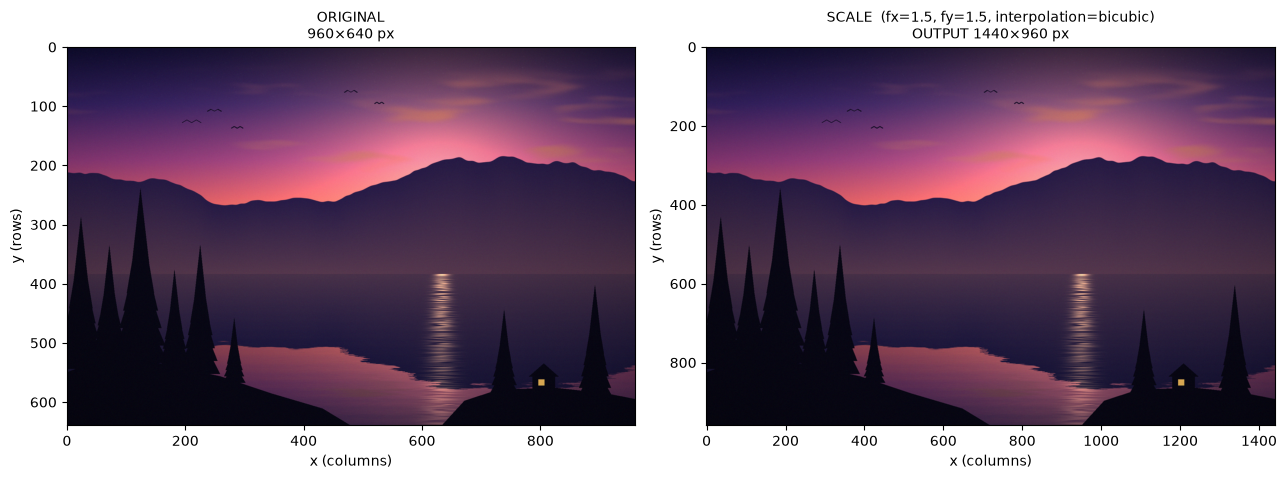

Saved -> saved_results\01_scale_enlarge_proportional_1.5x_bicubic.png   (1440x960 px)


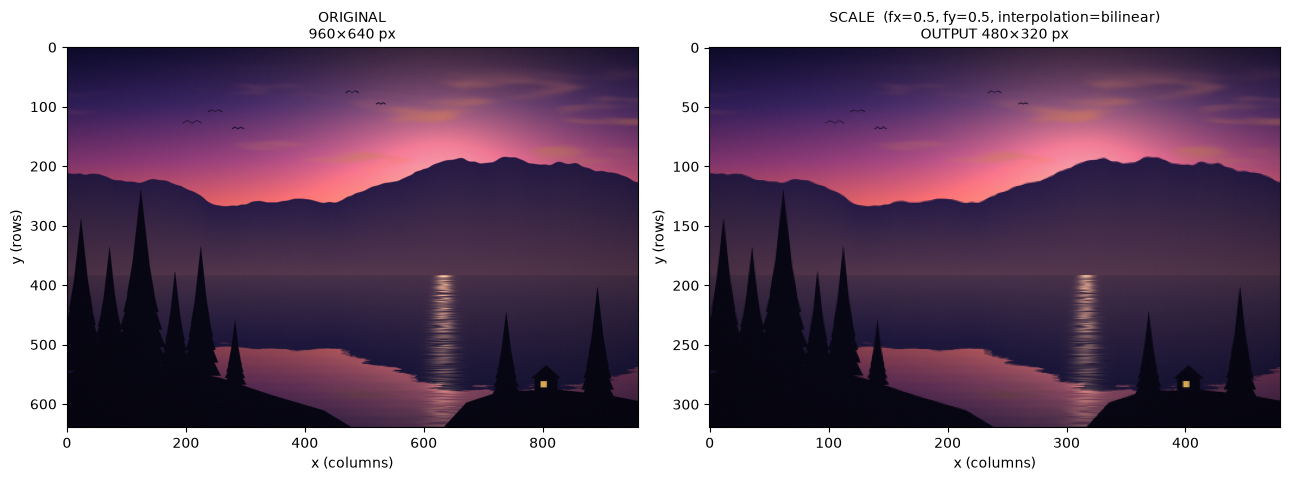

Saved -> saved_results\02_scale_reduce_proportional_0.5x_bilinear.png   (480x320 px)


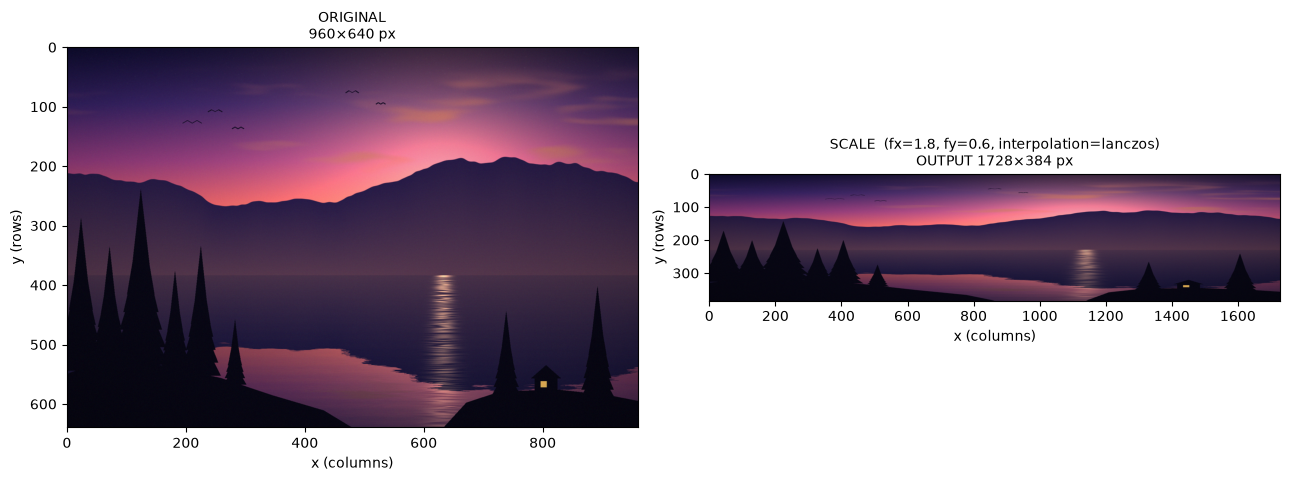

Saved -> saved_results\03_scale_nonproportional_fx1.8_fy0.6_lanczos.png   (1728x384 px)

Case                 | Type              | Output size  | Aspect w/h  | Distorted?
---------------------+-------------------+--------------+-------------+-----------
original             | -                 | 960x640      | 1.500       | no        
---------------------+-------------------+--------------+-------------+-----------
enlarge  fx=fy=1.5   | proportional      | 1440x960     | 1.500       | no        
---------------------+-------------------+--------------+-------------+-----------
reduce   fx=fy=0.5   | proportional      | 480x320      | 1.500       | no        
---------------------+-------------------+--------------+-------------+-----------
fx=1.8, fy=0.6       | NON-proportional  | 1728x384     | 4.500       | yes       
---------------------+-------------------+--------------+-------------+-----------


In [8]:
print(f"Original: {W}x{H}, aspect ratio w/h = {W/H:.3f}\n")
up   = run_demo("scale", "01_scale_enlarge_proportional_1.5x_bicubic.png",   fx=1.5, fy=1.5, interpolation="bicubic")
down = run_demo("scale", "02_scale_reduce_proportional_0.5x_bilinear.png",   fx=0.5, fy=0.5, interpolation="bilinear")
skew = run_demo("scale", "03_scale_nonproportional_fx1.8_fy0.6_lanczos.png", fx=1.8, fy=0.6, interpolation="lanczos")

rows = []
for label, img, kind in [("original", original, "-"),
                         ("enlarge  fx=fy=1.5", up, "proportional"),
                         ("reduce   fx=fy=0.5", down, "proportional"),
                         ("fx=1.8, fy=0.6", skew, "NON-proportional")]:
    h_, w_ = img.shape[:2]
    rows.append([label, kind, f"{w_}x{h_}", f"{w_/h_:.3f}", "yes" if abs(w_/h_ - W/H) > 0.01 else "no"])
print()
print_table(["Case", "Type", "Output size", "Aspect w/h", "Distorted?"], rows, [20, 17, 12, 11, 10])

**Observation.** With `fx = fy` the width-to-height ratio stays 1.500 (only rounding to whole pixels can change it by a tiny amount). With `fx ≠ fy` the ratio is multiplied by `fx/fy`: for `fx=1.8, fy=0.6` it grows by a factor of 3 (1.5 → 4.5), so the scene is visibly stretched horizontally — this is aspect-ratio distortion.

### 7.2 Cropping — right and bottom are exclusive

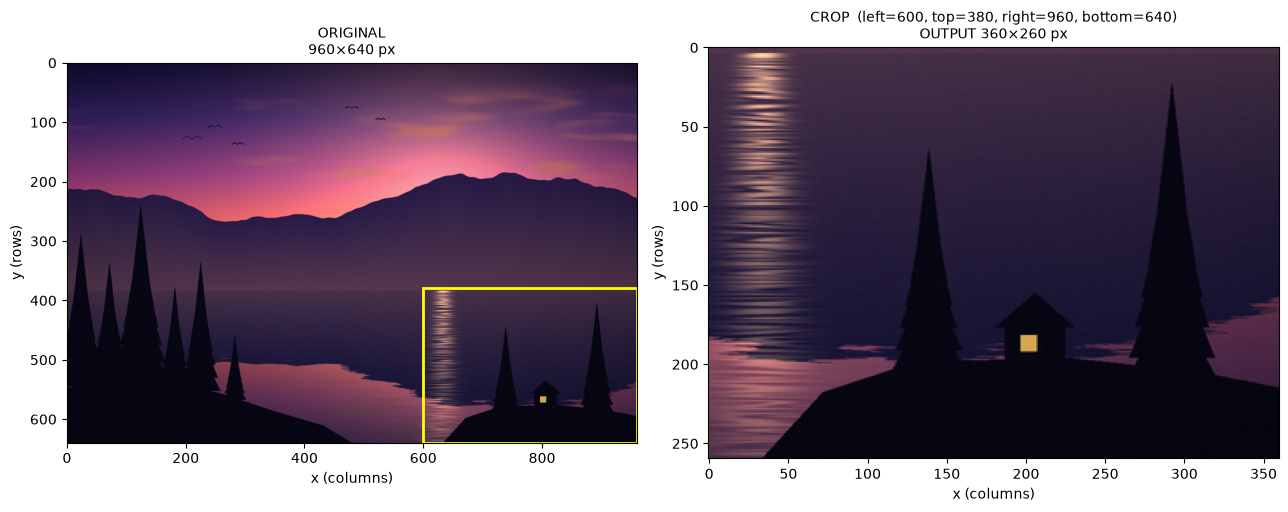

Saved -> saved_results\04_crop_cabin_and_lake_600_380_960_640.png   (360x260 px)


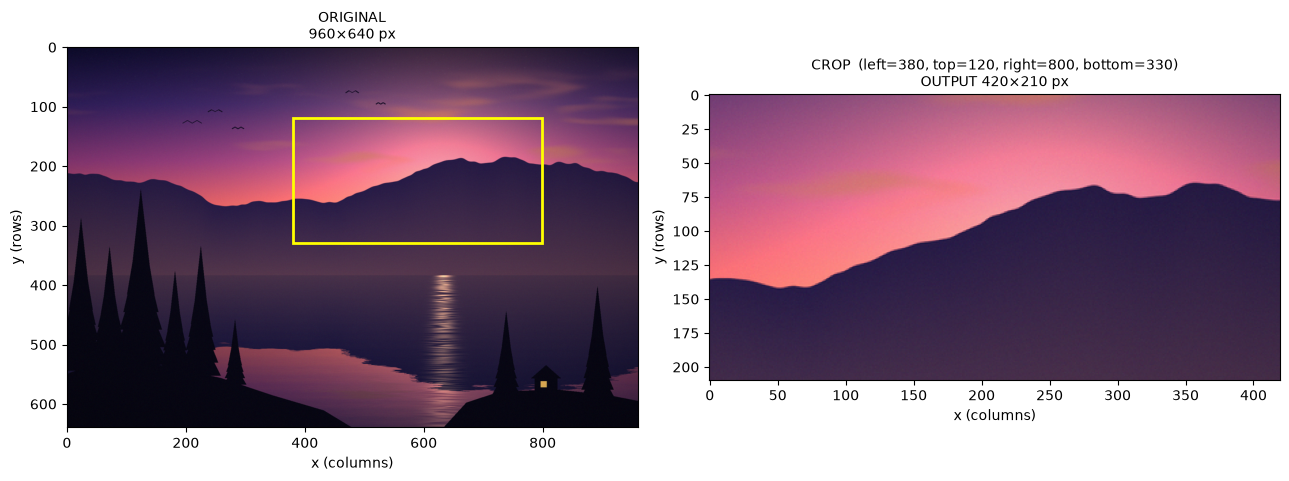

Saved -> saved_results\05_crop_mountain_sky_380_120_800_330.png   (420x210 px)
crop 1: width = right-left = 360, height = bottom-top = 260  ->  array shape (260, 360, 3)
crop 2: width = right-left = 420, height = bottom-top = 210  ->  array shape (210, 420, 3)


In [9]:
crop1 = run_demo("crop", "04_crop_cabin_and_lake_600_380_960_640.png", box=(600, 380, 960, 640),
                 left=600, top=380, right=960, bottom=640)
crop2 = run_demo("crop", "05_crop_mountain_sky_380_120_800_330.png", box=(380, 120, 800, 330),
                 left=380, top=120, right=800, bottom=330)
for name, c, (l, t, r, b) in [("crop 1", crop1, (600, 380, 960, 640)), ("crop 2", crop2, (380, 120, 800, 330))]:
    print(f"{name}: width = right-left = {r-l}, height = bottom-top = {b-t}  ->  array shape {c.shape}")

**Observation.** Output size is `(right − left) × (bottom − top)`. Because `right` and `bottom` are exclusive, the full image is `left=0, top=0, right=W, bottom=H`. In array form the crop is `image[top:bottom, left:right]` (rows first).

### 7.3 Flipping — horizontal, vertical and both

Saved -> saved_results\06_flip_horizontal.png   (960x640 px)
Saved -> saved_results\06_flip_vertical.png   (960x640 px)
Saved -> saved_results\06_flip_both.png   (960x640 px)


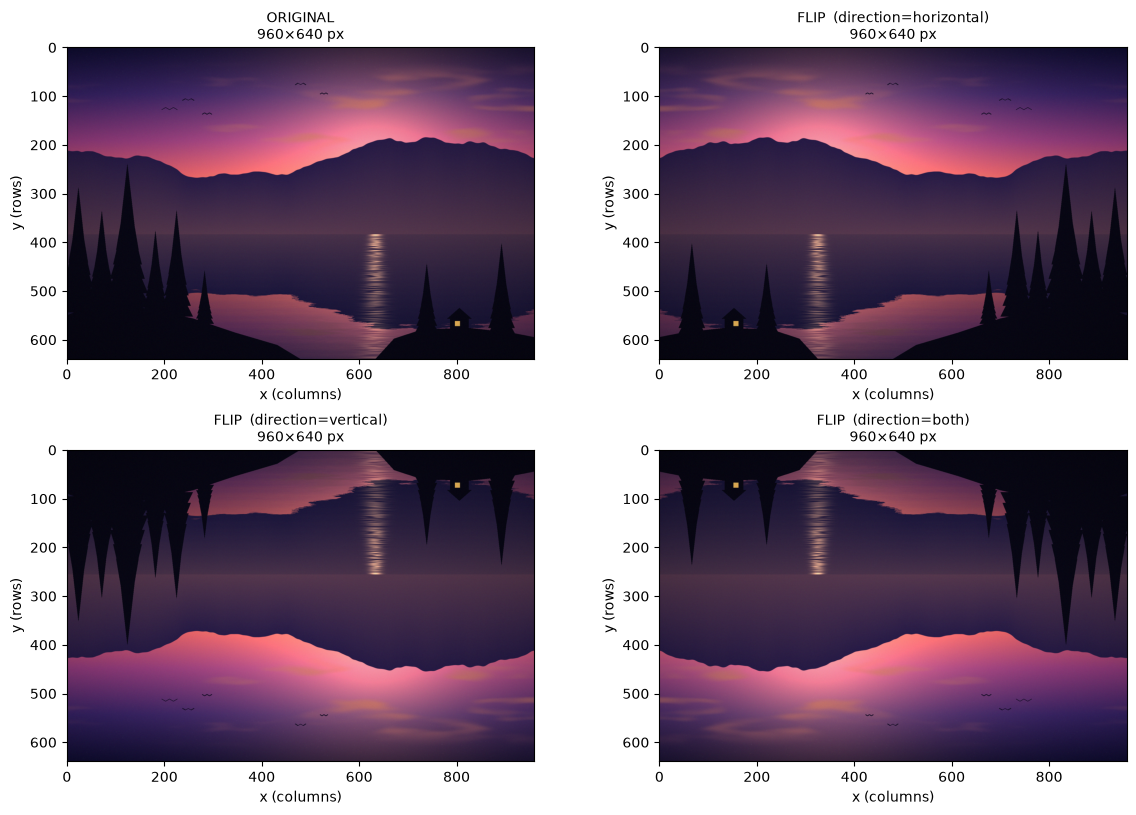

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8.2))
panels = [("ORIGINAL", original)]
for direction in FLIP_DIRECTIONS:
    out = transform(original, "flip", direction=direction)
    panels.append((f"FLIP  (direction={direction})", out))
    save_result(out, f"06_flip_{direction}.png")
for ax, (title, img) in zip(axes.ravel(), panels):
    ax.imshow(img); ax.set_title(f"{title}\n{img.shape[1]}×{img.shape[0]} px", fontsize=10)
    ax.set_xlabel("x (columns)"); ax.set_ylabel("y (rows)")
plt.tight_layout(); plt.show()

**Observation.** *Horizontal* mirrors left ↔ right (the cabin moves to the left side and the pines to the right); *vertical* mirrors top ↔ bottom (the sky ends up at the bottom); *both* is the same as a 180° rotation. Flipping never changes the image size.

### 7.4 Translation — shifts in opposite directions (canvas size is kept)

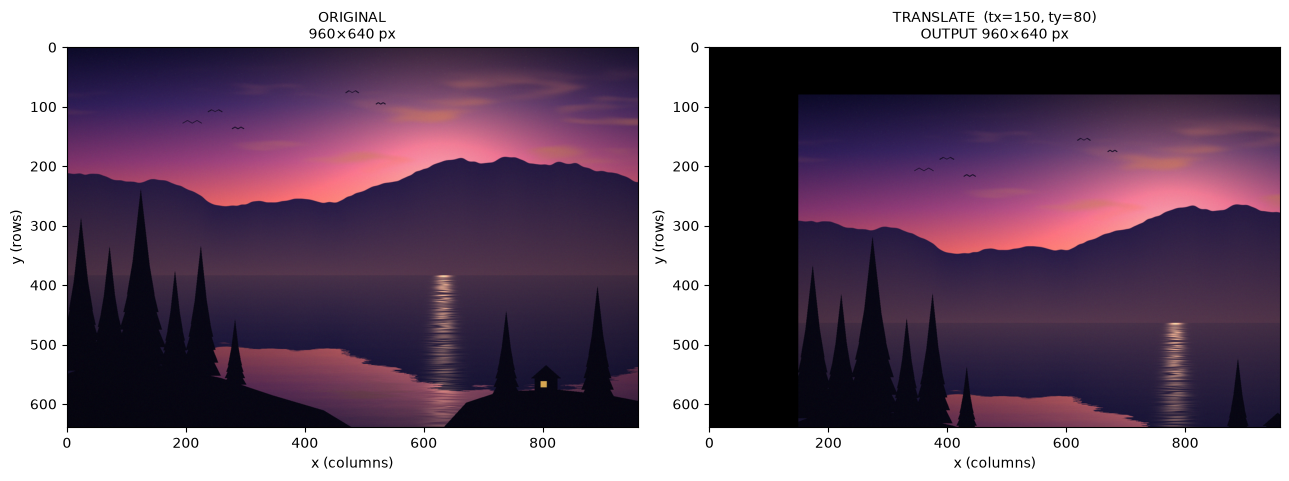

Saved -> saved_results\07_translate_tx+150_ty+80.png   (960x640 px)
tx=+150, ty=+80: exposed background = 160,800 px (formula W*H - (W-|tx|)*(H-|ty|) = 160,800); the same number of image pixels are clipped away



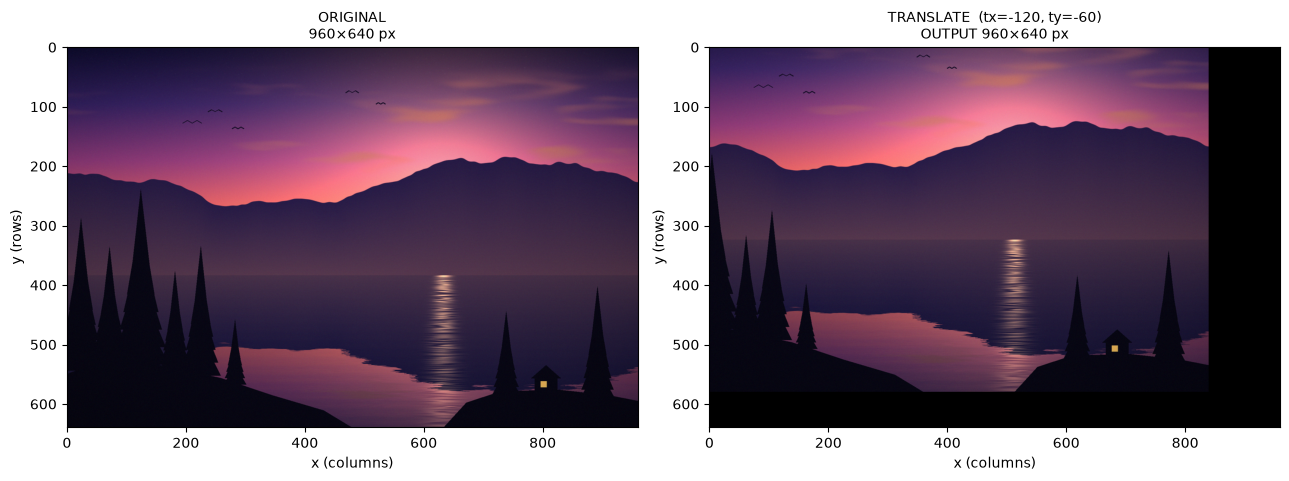

Saved -> saved_results\08_translate_tx-120_ty-60.png   (960x640 px)
tx=-120, ty=-60: exposed background = 127,200 px (formula W*H - (W-|tx|)*(H-|ty|) = 127,200); the same number of image pixels are clipped away

Affine matrix for tx=+150, ty=+80:
 [[  1.   0. 150.]
 [  0.   1.  80.]]


In [11]:
def exposed_pixels(tx, ty):
    """Count background pixels exposed by an integer shift, measured on an all-white test image."""
    white = np.full((H, W, 3), 255, np.uint8)
    moved = transform(white, "translate", tx=tx, ty=ty)
    return int(np.count_nonzero(np.any(moved != 255, axis=2)))

for fname, tx, ty in [("07_translate_tx+150_ty+80.png", 150, 80), ("08_translate_tx-120_ty-60.png", -120, -60)]:
    run_demo("translate", fname, tx=tx, ty=ty)
    expected = W * H - (W - abs(tx)) * (H - abs(ty))
    print(f"tx={tx:+d}, ty={ty:+d}: exposed background = {exposed_pixels(tx, ty):,} px "
          f"(formula W*H - (W-|tx|)*(H-|ty|) = {expected:,}); the same number of image pixels are clipped away\n")

print("Affine matrix for tx=+150, ty=+80:\n", translation_matrix(150, 80))

**Observation.** Positive `tx` moves the image to the **right** and positive `ty` moves it **down** (image coordinates: y points downward); negative values move it left/up. The canvas stays 960×640: pixels pushed outside the canvas are **clipped (lost, no wrap-around)** and the opposite edges expose **black background** (the declared `BACKGROUND_COLOR`).

### 7.5 Rotation — positive and negative angles, with and without canvas expansion

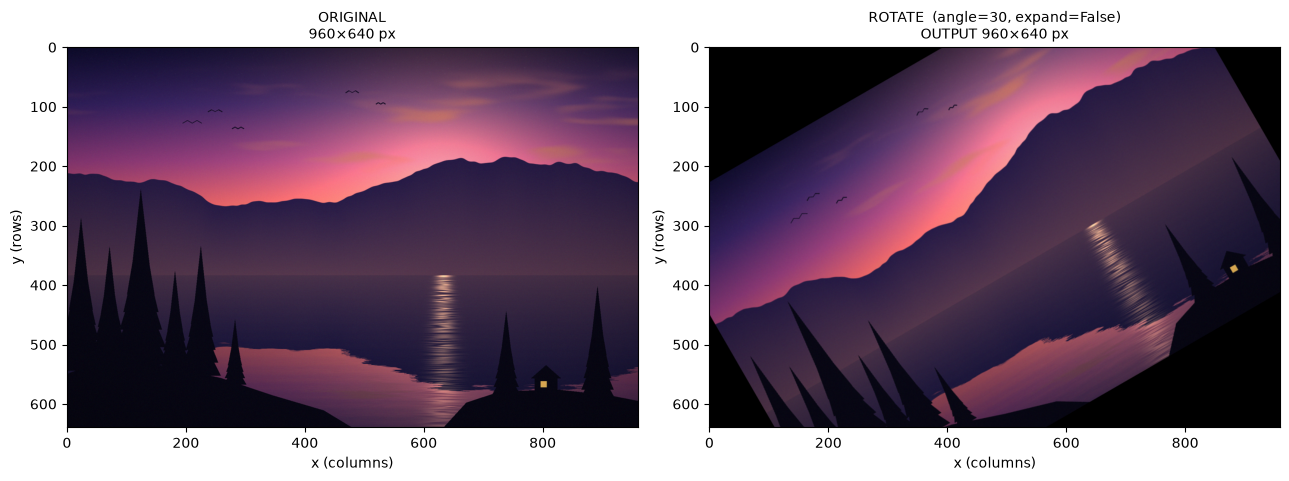

Saved -> saved_results\09_rotate_+30_no_expand.png   (960x640 px)


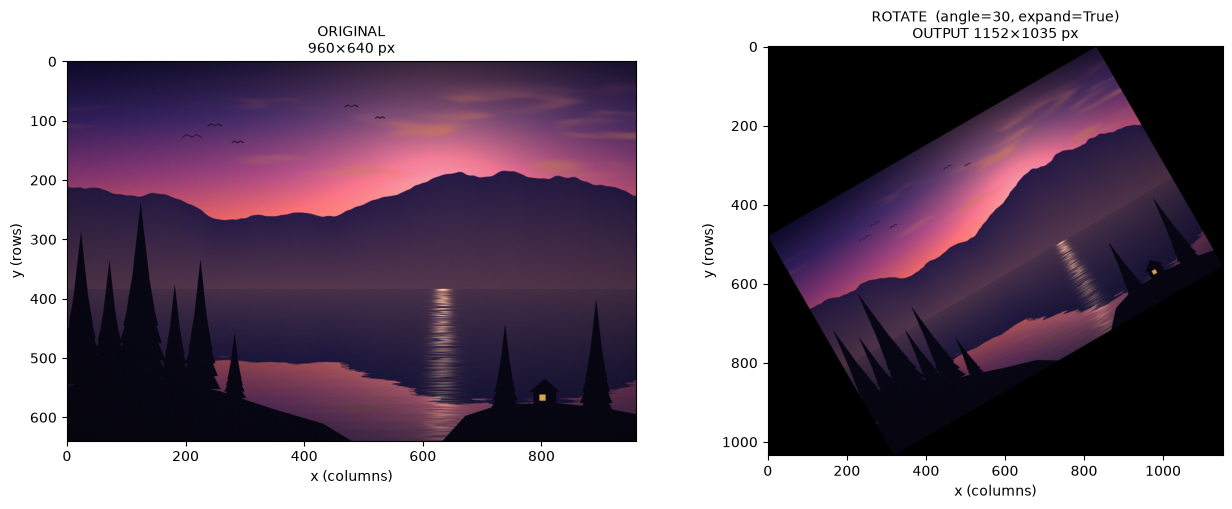

Saved -> saved_results\10_rotate_+30_expand.png   (1152x1035 px)


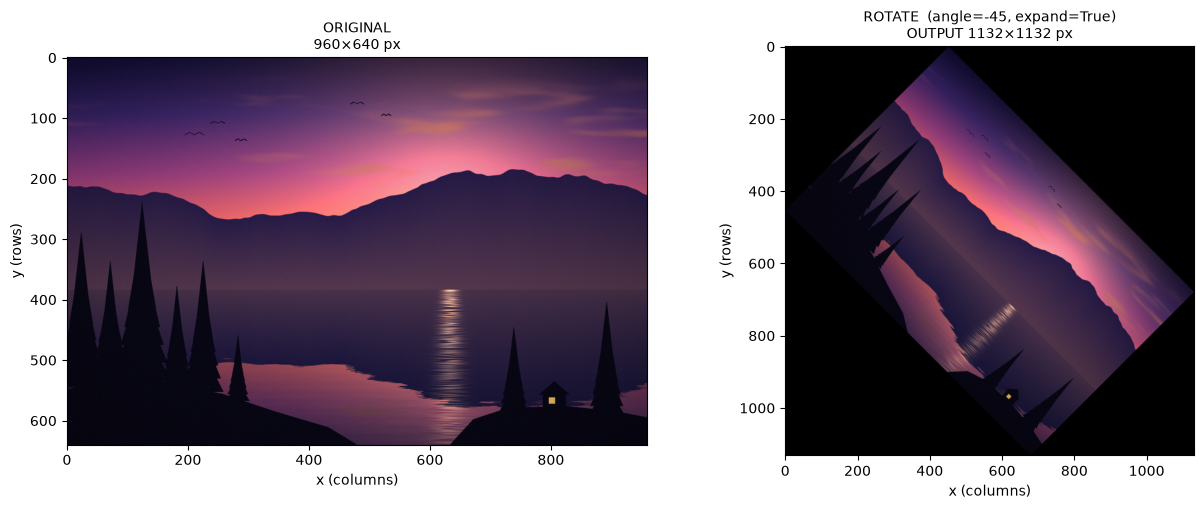

Saved -> saved_results\11_rotate_-45_expand.png   (1132x1132 px)

angle=+30: expected canvas (1152, 1035) (W|cos|+H|sin| , W|sin|+H|cos|), actual 1152x1035
angle=-45: expected canvas (1132, 1132) (W|cos|+H|sin| , W|sin|+H|cos|), actual 1132x1132
angle=+30, expand=False: canvas stays 960x640

Affine matrix for +30 degrees about the centre (no expansion):
 [[  0.866    0.5    -95.5092]
 [ -0.5      0.866  282.5549]]


In [18]:
r1 = run_demo("rotate", "09_rotate_+30_no_expand.png",  angle=30,  expand=False)
r2 = run_demo("rotate", "10_rotate_+30_expand.png",     angle=30,  expand=True)
r3 = run_demo("rotate", "11_rotate_-45_expand.png",     angle=-45, expand=True)

def expanded_size(angle):
    c, s = abs(math.cos(math.radians(angle))), abs(math.sin(math.radians(angle)))
    return math.ceil(round(W * c + H * s, 6)), math.ceil(round(W * s + H * c, 6))

print()
for angle, img in [(30, r2), (-45, r3)]:
    print(f"angle={angle:+d}: expected canvas {expanded_size(angle)} (W|cos|+H|sin| , W|sin|+H|cos|), actual {img.shape[1]}x{img.shape[0]}")
print(f"angle=+30, expand=False: canvas stays {r1.shape[1]}x{r1.shape[0]}")
M, _, _ = rotation_matrix(W, H, 30 % 360.0, False)
print("\nAffine matrix for +30 degrees about the centre (no expansion):\n", np.round(M, 4))

**Observation.** Rotation is about the image centre. A **positive angle turns the image counter-clockwise** as seen on screen; a negative angle turns it clockwise (verified automatically in section 10). With `expand=False` the canvas keeps its size, so the corners of the rotated picture are **cut off** and empty corners are filled with black; with `expand=True` the canvas grows to hold the entire rotated image (at the cost of larger black corner areas).

## 8. Interpolation comparison on the same enlarged patch
A small 80×60 patch containing sharp edges (cabin roof, lit window, shoreline) is enlarged 8× with each of the four interpolation methods. Besides looking at the images, three simple numbers are measured: how many *new* colours appear, the mean edge strength (Sobel gradient), and the share of pixels that overshoot the original patch's colour range (ringing).

Saved -> saved_results\12_interpolation_nearest_x8.png   (640x480 px)
Saved -> saved_results\12_interpolation_bilinear_x8.png   (640x480 px)
Saved -> saved_results\12_interpolation_bicubic_x8.png   (640x480 px)
Saved -> saved_results\12_interpolation_lanczos_x8.png   (640x480 px)


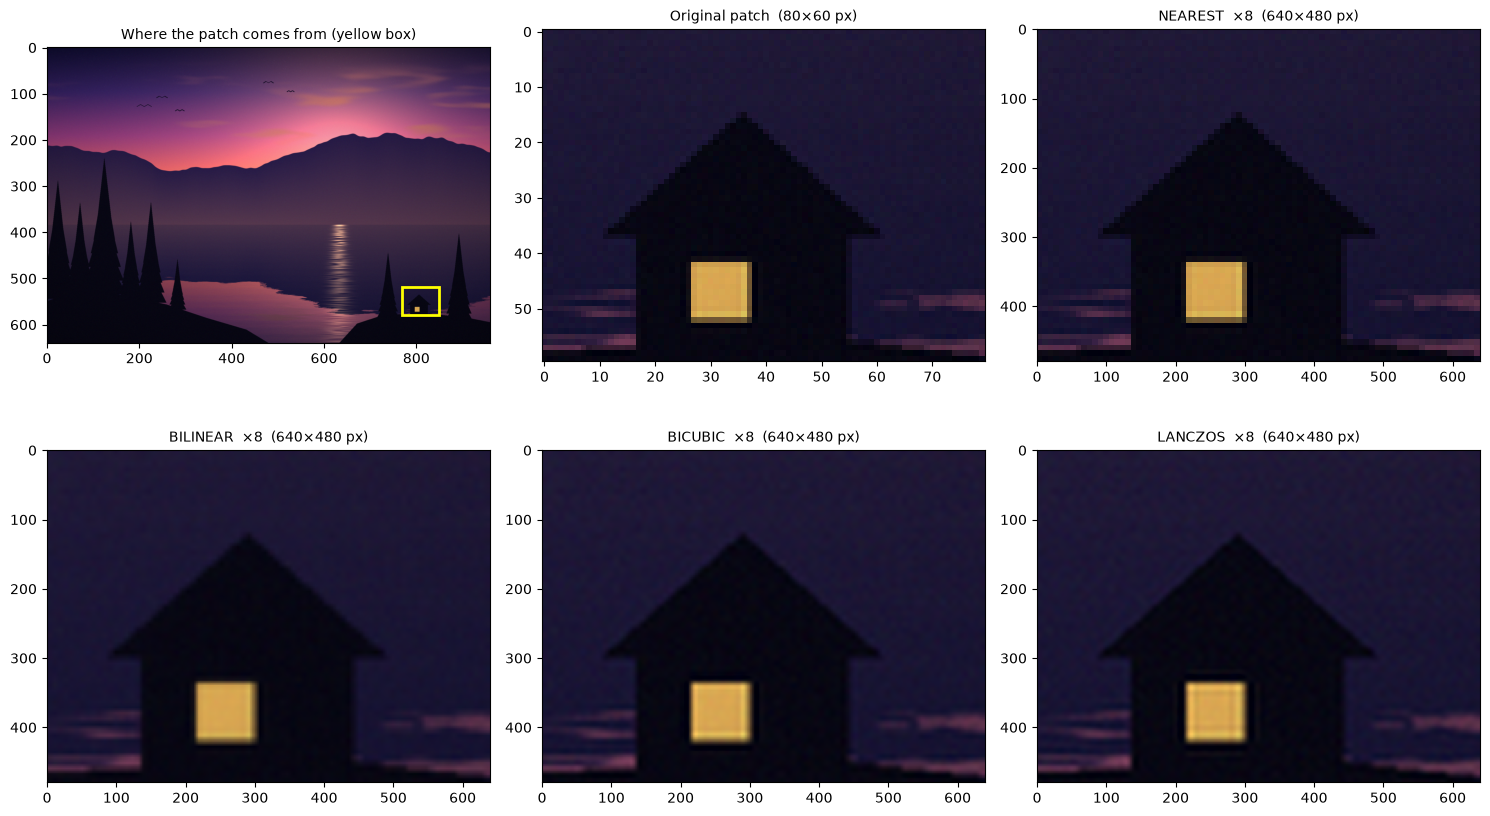


Method    | Size      | New colours  | Mean edge strength | Overshoot 
----------+-----------+--------------+--------------------+-----------
nearest   | 640x480   | 0            | 5.6                | 0.00 %    
----------+-----------+--------------+--------------------+-----------
bilinear  | 640x480   | 7,524        | 4.9                | 0.00 %    
----------+-----------+--------------+--------------------+-----------
bicubic   | 640x480   | 10,581       | 5.7                | 0.42 %    
----------+-----------+--------------+--------------------+-----------
lanczos   | 640x480   | 11,972       | 6.0                | 0.39 %    
----------+-----------+--------------+--------------------+-----------


In [13]:
box = (770, 520, 850, 580)                                  # left, top, right, bottom of the patch
patch = transform(original, "crop", left=box[0], top=box[1], right=box[2], bottom=box[3])
FACTOR = 8
enlarged = {m: transform(patch, "scale", fx=FACTOR, fy=FACTOR, interpolation=m) for m in INTERPOLATIONS}

fig, axes = plt.subplots(2, 3, figsize=(15, 8.6))
axes[0, 0].imshow(original); axes[0, 0].set_title("Where the patch comes from (yellow box)", fontsize=10)
axes[0, 0].add_patch(plt.Rectangle((box[0] - 0.5, box[1] - 0.5), box[2] - box[0], box[3] - box[1],
                                   fill=False, edgecolor="yellow", linewidth=2))
axes[0, 1].imshow(patch, interpolation="nearest")
axes[0, 1].set_title(f"Original patch  ({patch.shape[1]}×{patch.shape[0]} px)", fontsize=10)
for ax, (name, img) in zip([axes[0, 2], axes[1, 0], axes[1, 1], axes[1, 2]], enlarged.items()):
    ax.imshow(img, interpolation="nearest")                 # show pixels as they are, no extra smoothing by Matplotlib
    ax.set_title(f"{name.upper()}  ×{FACTOR}  ({img.shape[1]}×{img.shape[0]} px)", fontsize=10)
    save_result(img, f"12_interpolation_{name}_x{FACTOR}.png")
plt.tight_layout(); plt.show()

# ---- simple measurements ----
def mean_edge_strength(img):
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).astype(np.float32)
    return float(np.mean(np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))))

lo, hi = patch.min(axis=(0, 1)), patch.max(axis=(0, 1))       # per-channel colour range of the original patch
original_colours = {tuple(c) for c in patch.reshape(-1, 3)}
rows = []
for name, img in enlarged.items():
    colours = {tuple(c) for c in img.reshape(-1, 3)}
    overshoot = np.mean(np.any((img < lo) | (img > hi), axis=2)) * 100
    rows.append([name, f"{img.shape[1]}x{img.shape[0]}", f"{len(colours - original_colours):,}",
                 f"{mean_edge_strength(img):.1f}", f"{overshoot:.2f} %"])
print()
print_table(["Method", "Size", "New colours", "Mean edge strength", "Overshoot"], rows, [9, 9, 12, 18, 10])

**Observations (what the images and the numbers show).**

* **Nearest neighbour** – every original pixel simply becomes an 8×8 block. Edges turn into hard **stair-steps** (see the jagged roof line and the blocky window). It creates **no new colours** (0 in the table), so nothing is blurred, but the result looks pixelated.
* **Bilinear** – averages the 4 nearest pixels, so the result is **smooth but soft/blurry**: roof and window edges are spread over several pixels. It has the lowest mean edge strength (4.9) and **no overshoot** (it can never go outside the original colour range).
* **Bicubic** – uses a 4×4 neighbourhood; edges are **noticeably crisper than bilinear** (edge strength 5.7) while still smooth. The price is a little **ringing**: 0.42 % of the pixels overshoot the original colour range, visible as faint dark/light halos around the lit window.
* **Lanczos** – uses an even wider neighbourhood and gives the **sharpest** edges (edge strength 6.0, the highest), with similar slight halos around the window (0.39 % overshoot).

For enlargement, bilinear is the safest smooth choice, bicubic/Lanczos give the sharpest detail, and nearest neighbour is best only when hard pixel edges must be preserved.

## 9. Input validation: rejected inputs and accepted boundary inputs
Every case below is run through the real validation code. Some use **typed text** (`transform_from_text`, as the prompts do), others call `transform` **directly** with a bad Python value. A case counts as correct only when it is rejected with a `TransformError`. No case crashes the notebook.

In [14]:
def T(operation, **kw):            # direct call with Python values
    return lambda: transform(original, operation, **kw)

def X(operation, **kw):            # call with typed text, as entered at a prompt
    return lambda: transform_from_text(original, operation, **kw)

nan, inf = float("nan"), float("inf")
cases = [
    # operation, rejected input, how it is given, runner
    ("scale",     "fx = 0",                         "direct", T("scale", fx=0, fy=1, interpolation="bilinear")),
    ("scale",     "fy = -1.5 (negative)",           "direct", T("scale", fx=1, fy=-1.5, interpolation="bilinear")),
    ("scale",     "fx typed as 'abc'",              "text",   X("scale", fx="abc", fy="1", interpolation="bilinear")),
    ("scale",     "fx typed as 'nan'",              "text",   X("scale", fx="nan", fy="1", interpolation="bilinear")),
    ("scale",     "fy = infinity",                  "direct", T("scale", fx=1, fy=inf, interpolation="bilinear")),
    ("scale",     "fx = 0.0001 (empty output)",     "direct", T("scale", fx=0.0001, fy=1, interpolation="bilinear")),
    ("scale",     "fx = fy = 1000 (too large)",     "direct", T("scale", fx=1000, fy=1000, interpolation="nearest")),
    ("scale",     "interpolation = 'cubic-spline'", "direct", T("scale", fx=2, fy=2, interpolation="cubic-spline")),
    ("scale",     "fy missing",                     "direct", T("scale", fx=2, interpolation="bilinear")),
    ("crop",      "left = -5",                      "direct", T("crop", left=-5, top=0, right=100, bottom=100)),
    ("crop",      "right = left (empty region)",    "direct", T("crop", left=300, top=0, right=300, bottom=100)),
    ("crop",      f"right = 2000 (> width {W})",    "direct", T("crop", left=0, top=0, right=2000, bottom=100)),
    ("crop",      f"bottom = 700 (> height {H})",   "direct", T("crop", left=0, top=0, right=100, bottom=700)),
    ("crop",      "top = 10.5 (not an integer)",    "direct", T("crop", left=0, top=10.5, right=100, bottom=100)),
    ("crop",      "left typed as 'ten'",            "text",   X("crop", left="ten", top="0", right="100", bottom="100")),
    ("flip",      "direction = 'diagonal'",         "direct", T("flip", direction="diagonal")),
    ("flip",      "direction = 5 (not text)",       "direct", T("flip", direction=5)),
    ("flip",      "direction missing",              "direct", T("flip")),
    ("translate", "tx = NaN",                       "direct", T("translate", tx=nan, ty=0)),
    ("translate", "ty typed as 'ten'",              "text",   X("translate", tx="5", ty="ten")),
    ("translate", "tx = infinity",                  "direct", T("translate", tx=inf, ty=0)),
    ("translate", "ty missing",                     "direct", T("translate", tx=5)),
    ("rotate",    "angle typed as 'abc'",           "text",   X("rotate", angle="abc", expand="yes")),
    ("rotate",    "angle = NaN",                    "direct", T("rotate", angle=nan, expand=True)),
    ("rotate",    "angle = -infinity",              "direct", T("rotate", angle=-inf, expand=True)),
    ("rotate",    "expand = 'maybe'",               "text",   X("rotate", angle="10", expand="maybe")),
    ("rotate",    "expand = 2 (not True/False)",    "direct", T("rotate", angle=10, expand=2)),
    ("rotate",    "expand missing",                 "direct", T("rotate", angle=10)),
    ("(general)", "unknown operation 'shear'",      "direct", T("shear", k=1)),
    ("(general)", "extra parameter for flip",       "direct", T("flip", direction="both", angle=5)),
    ("(general)", "image = None",                   "direct", lambda: transform(None, "flip", direction="both")),
    ("(general)", "empty image (0 x 50 pixels)",    "direct", lambda: transform(np.zeros((0, 50, 3), np.uint8), "flip", direction="both")),
]

rows, wrongly_accepted = [], 0
for op, bad, how, run in cases:
    try:
        run()
        rows.append([op, bad, how, "!! NOT REJECTED"]); wrongly_accepted += 1
    except TransformError as err:
        rows.append([op, bad, how, f"REJECTED: {err}"])
print_table(["Operation", "Invalid input", "Given as", "Result / message"], rows, [10, 30, 8, 78])
print(f"\n{len(cases)} invalid inputs tried, {len(cases) - wrongly_accepted} rejected with a clear message, {wrongly_accepted} wrongly accepted.")

Operation  | Invalid input                  | Given as | Result / message                                                              
-----------+--------------------------------+----------+-------------------------------------------------------------------------------
scale      | fx = 0                         | direct   | REJECTED: scale factors must be greater than zero (got fx=0, fy=1)            
-----------+--------------------------------+----------+-------------------------------------------------------------------------------
scale      | fy = -1.5 (negative)           | direct   | REJECTED: scale factors must be greater than zero (got fx=1, fy=-1.5)         
-----------+--------------------------------+----------+-------------------------------------------------------------------------------
scale      | fx typed as 'abc'              | text     | REJECTED: 'fx': 'abc' is not a number                                         
-----------+--------------------------------+---

In [15]:
# Valid boundary inputs that must NOT be rejected: zero, negative, minimum and maximum-edge values
accepted = [
    ("translate", "tx=0, ty=0 (zero offsets)",              T("translate", tx=0, ty=0)),
    ("translate", "tx=-40, ty=-25 (negative offsets)",      T("translate", tx=-40, ty=-25)),
    ("translate", "tx=0.0, ty=-0.0",                        T("translate", tx=0.0, ty=-0.0)),
    ("rotate",    "angle=0, expand=False",                  T("rotate", angle=0, expand=False)),
    ("rotate",    "angle=-90, expand=True (negative angle)", T("rotate", angle=-90, expand=True)),
    ("rotate",    "angle=720.5, expand=False (large angle)", T("rotate", angle=720.5, expand=False)),
    ("crop",      "full frame (0, 0, W, H)",                T("crop", left=0, top=0, right=W, bottom=H)),
    ("crop",      "single pixel (0, 0, 1, 1)",              T("crop", left=0, top=0, right=1, bottom=1)),
    ("scale",     "fx=fy=1 (identity factors)",             T("scale", fx=1, fy=1, interpolation="lanczos")),
    ("scale",     "fx=1/W, fy=1/H (smallest valid output, 1x1)", T("scale", fx=1 / W, fy=1 / H, interpolation="bilinear")),
    ("flip",      "direction=' BOTH ' (case/space tolerant)", T("flip", direction=" BOTH ")),
]
rows = []
for op, label, run in accepted:
    try:
        out = run()
        rows.append([op, label, "ACCEPTED", f"{out.shape[1]}x{out.shape[0]} px"])
    except TransformError as err:
        rows.append([op, label, "!! REJECTED", str(err)])
print_table(["Operation", "Valid boundary input", "Result", "Output / message"], rows, [10, 44, 11, 40])

Operation  | Valid boundary input                         | Result      | Output / message                        
-----------+----------------------------------------------+-------------+-----------------------------------------
translate  | tx=0, ty=0 (zero offsets)                    | ACCEPTED    | 960x640 px                              
-----------+----------------------------------------------+-------------+-----------------------------------------
translate  | tx=-40, ty=-25 (negative offsets)            | ACCEPTED    | 960x640 px                              
-----------+----------------------------------------------+-------------+-----------------------------------------
translate  | tx=0.0, ty=-0.0                              | ACCEPTED    | 960x640 px                              
-----------+----------------------------------------------+-------------+-----------------------------------------
rotate     | angle=0, expand=False                        | ACCEPTED    | 960x64

## 10. Identity and correctness checks
*Identity cases* (scale factor 1, zero translation, zero rotation) must return exactly the original pixels. A few extra checks confirm the geometry itself: flip mapping, crop equals slicing, exact integer shifts, the positive-angle direction, the expanded canvas size and that the original was never modified.

In [16]:
results = []                      # (test, expected, actual, passed)
def record(test, expected, actual, passed):
    results.append([test, expected, actual, "Pass" if passed else "FAIL"])

def identical(a, b):
    same_shape = a.shape == b.shape
    diff = int(np.abs(a.astype(int) - b.astype(int)).max()) if same_shape else -1
    return same_shape and diff == 0, f"shape {a.shape}, max |diff| = {diff}"

# ---------------- identity cases ----------------
for m in INTERPOLATIONS:
    ok, txt = identical(transform(original, "scale", fx=1, fy=1, interpolation=m), original)
    record(f"scale fx=fy=1 ({m})", "same size, identical pixels", txt, ok)
ok, txt = identical(transform(original, "translate", tx=0, ty=0), original)
record("translate tx=0, ty=0", "same size, identical pixels", txt, ok)
for exp in (False, True):
    ok, txt = identical(transform(original, "rotate", angle=0, expand=exp), original)
    record(f"rotate angle=0, expand={exp}", "same size, identical pixels", txt, ok)
ok, txt = identical(transform(original, "rotate", angle=360, expand=False), original)
record("rotate angle=360", "same as angle 0 (identity)", txt, ok)
ok, txt = identical(transform(original, "crop", left=0, top=0, right=W, bottom=H), original)
record("crop full frame", "identical to original", txt, ok)
for d in ("horizontal", "vertical", "both"):
    twice = transform(transform(original, "flip", direction=d), "flip", direction=d)
    ok, txt = identical(twice, original)
    record(f"flip {d} applied twice", "identical to original", txt, ok)

# ---------------- geometry correctness ----------------
f = transform(original, "flip", direction="horizontal")
record("flip horizontal mapping", "out[:, 0] == original[:, -1]", f"equal = {np.array_equal(f[:, 0], original[:, -1])}",
       np.array_equal(f[:, 0], original[:, -1]))
c = transform(original, "crop", left=100, top=50, right=400, bottom=250)
record("crop equals slicing", "out == original[50:250, 100:400], shape (200, 300, 3)",
       f"shape {c.shape}, equal = {np.array_equal(c, original[50:250, 100:400])}",
       c.shape == (200, 300, 3) and np.array_equal(c, original[50:250, 100:400]))
t = transform(original, "translate", tx=40, ty=25)
shift_ok = np.array_equal(t[25:, 40:], original[:-25, :-40]) and not t[:25].any() and not t[:, :40].any()
record("translate +40, +25 (right, down)", "pixels move exactly; top 25 rows and left 40 cols are background",
       f"moved block equal and exposed area black = {shift_ok}", shift_ok)
t = transform(original, "translate", tx=-30, ty=-10)
shift_ok = np.array_equal(t[:-10, :-30], original[10:, 30:]) and not t[-10:].any() and not t[:, -30:].any()
record("translate -30, -10 (left, up)", "pixels move exactly; bottom 10 rows and right 30 cols are background",
       f"moved block equal and exposed area black = {shift_ok}", shift_ok)
r90 = transform(original, "rotate", angle=90, expand=True)
ok = r90.shape == (W, H, 3) and np.array_equal(r90, np.rot90(original, 1))
record("rotate +90, expand=True", "equals np.rot90(original) (counter-clockwise), shape (960, 640, 3)",
       f"shape {r90.shape}, equal = {np.array_equal(r90, np.rot90(original, 1))}", ok)
marker = np.zeros((101, 101, 3), np.uint8); marker[50, 90:101] = 255          # white bar at the RIGHT edge, middle row
turned = transform(marker, "rotate", angle=90, expand=False)
at_top = turned[:11, 50].min() > 200 and turned[50, 90:].max() < 50
record("positive angle direction", "white mark on the right edge moves to the TOP for +90 (counter-clockwise)",
       f"mark at top = {at_top}", at_top)
r30 = transform(original, "rotate", angle=30, expand=True)
record("expanded canvas size, 30 degrees", f"(W|cos|+H|sin|, W|sin|+H|cos|) = {expanded_size(30)}",
       f"{r30.shape[1]}x{r30.shape[0]}", (r30.shape[1], r30.shape[0]) == expanded_size(30))
s = transform(original, "scale", fx=2, fy=0.5, interpolation="bilinear")
record("scale fx=2, fy=0.5 size", f"{W*2}x{H//2}", f"{s.shape[1]}x{s.shape[0]}", s.shape[:2] == (H // 2, W * 2))
new = transform(original, "flip", direction="both")
record("result is a new array", "does not share memory with the original", f"shares memory = {np.shares_memory(new, original)}",
       not np.shares_memory(new, original))
record("original unchanged after all tests", "SHA-256 fingerprint equals the one stored at load time",
       "fingerprint equal = " + str(hashlib.sha256(original.tobytes()).hexdigest() == original_digest),
       hashlib.sha256(original.tobytes()).hexdigest() == original_digest)

print_table(["Test", "Expected behaviour", "Actual behaviour", "Result"], results, [34, 46, 52, 6])
passed = sum(r[3] == "Pass" for r in results)
print(f"\n{passed} / {len(results)} checks passed.")

Test                               | Expected behaviour                             | Actual behaviour                                     | Result
-----------------------------------+------------------------------------------------+------------------------------------------------------+-------
scale fx=fy=1 (nearest)            | same size, identical pixels                    | shape (640, 960, 3), max |diff| = 0                  | Pass  
-----------------------------------+------------------------------------------------+------------------------------------------------------+-------
scale fx=fy=1 (bilinear)           | same size, identical pixels                    | shape (640, 960, 3), max |diff| = 0                  | Pass  
-----------------------------------+------------------------------------------------+------------------------------------------------------+-------
scale fx=fy=1 (bicubic)            | same size, identical pixels                    | shape (640, 960, 3), max |

## 11. Brief explanations

**Image coordinates vs. array indexing.** Image coordinates are written **(x, y)**: *x* grows to the right, *y* grows **downward**, and the origin (0, 0) is the **top-left** corner; width = number of columns, height = number of rows. NumPy stores the same picture as `array[row, column, channel]`, i.e. `array[y, x, c]`, so the order is swapped: the shape is `(height, width, 3)` and the pixel at x = 100, y = 50 is `original[50, 100]`. OpenCV size arguments go the other way round — `(width, height)` in `cv2.resize` and `cv2.warpAffine` — while slicing is `image[top:bottom, left:right]`. Mixing these orders up is the most common bug in this lab.

**Aspect-ratio distortion.** The aspect ratio is width / height. Scaling by `fx` and `fy` multiplies it by `fx / fy`. With `fx = fy` the shape of objects is preserved (proportional scaling); with `fx ≠ fy` objects are stretched or squeezed, e.g. `fx = 1.8, fy = 0.6` turns the 1.5 ratio into 4.5 (see section 7.1).

**Rotation canvas expansion.** Rotating inside the original W×H canvas (`expand=False`) cuts off the corners that leave the canvas and leaves empty corners. With `expand=True` the canvas is enlarged to  W' = ⌈W·|cos θ| + H·|sin θ|⌉ and H' = ⌈W·|sin θ| + H·|cos θ|⌉, so the entire rotated image fits; the new empty areas are filled with the background colour. Rotation is about the image centre and a positive angle is counter-clockwise on screen.

**Translation clipping.** Translation keeps the canvas size. Pixels pushed beyond an edge are **clipped** (discarded, not wrapped around) and the opposite side exposes `|tx|` columns / `|ty|` rows of background. The number of exposed pixels is W·H − (W − |tx|)·(H − |ty|) (section 7.4). Moving the image back does not restore the clipped pixels.

## 12. Saved files and conclusion

In [17]:
files = sorted(os.listdir(SAVE_DIR))
print(f"{len(files)} files in '{SAVE_DIR}/':")
for name in files:
    img = cv2.imread(os.path.join(SAVE_DIR, name))
    print(f"  {name:<52s} {img.shape[1]}x{img.shape[0]} px")
print("\nOriginal image untouched:", hashlib.sha256(original.tobytes()).hexdigest() == original_digest)

20 files in 'saved_results/':
  01_scale_enlarge_proportional_1.5x_bicubic.png       1440x960 px
  02_scale_reduce_proportional_0.5x_bilinear.png       480x320 px
  03_scale_nonproportional_fx1.8_fy0.6_lanczos.png     1728x384 px
  04_crop_cabin_and_lake_600_380_960_640.png           360x260 px
  05_crop_mountain_sky_380_120_800_330.png             420x210 px
  06_flip_both.png                                     960x640 px
  06_flip_horizontal.png                               960x640 px
  06_flip_vertical.png                                 960x640 px
  07_translate_tx+150_ty+80.png                        960x640 px
  08_translate_tx-120_ty-60.png                        960x640 px
  09_rotate_+30_no_expand.png                          960x640 px
  10_rotate_+30_expand.png                             1152x1035 px
  11_rotate_-45_expand.png                             1132x1132 px
  12_interpolation_bicubic_x8.png                      640x480 px
  12_interpolation_bilinear_x8.png      

**Conclusion.** One reusable `transform(image, operation, **params)` function performs scaling, cropping, flipping, translation and rotation with user-supplied values. All inputs are validated (type, finiteness, range, region, choices, output size) both when typed and inside `transform`; invalid input produces a clear `TransformError` message and can be corrected without a crash. Every operation was demonstrated with custom values, the four interpolation methods were compared, and the identity and correctness checks all passed.